# Customer Segmentation Using Data Analysis & Clustering

### Task 3 — Bank Customer Transaction Analysis

This project analyzes customer transaction behavior using data analysis, RFM analysis, and K-Means clustering to identify meaningful customer segments and develop business recommendations.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("bank_transactions.csv")

In [ ]:
df.head()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df.dtypes

In [ ]:
df.info()

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

In [ ]:
df["CustomerID"].nunique()

In [ ]:
df["TransactionID"].nunique()

In [ ]:
df["TransactionID"].duplicated().sum()

In [ ]:
df[["CustAccountBalance", "TransactionAmount (INR)"]].describe()

In [ ]:
df["TransactionDate"].min(), df["TransactionDate"].max()

In [ ]:
customer_transaction_counts = df["CustomerID"].value_counts()

customer_transaction_counts.describe()

In [ ]:
(customer_transaction_counts == 1).sum()

In [ ]:
(customer_transaction_counts > 1).sum()

In [ ]:
(customer_transaction_counts > 1).mean() * 100

In [ ]:
customer_transaction_counts.head(10)

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean["TransactionDate"] = pd.to_datetime(
    df_clean["TransactionDate"],
    dayfirst=True,
    errors="coerce"
)

In [ ]:
df_clean["TransactionDate"].isna().sum()

In [ ]:
df_clean["TransactionDate"].min(), df_clean["TransactionDate"].max()

In [ ]:
print(
    "Zero-amount transactions:",
    (df_clean["TransactionAmount (INR)"] == 0).sum()
)

print(
    "Negative-amount transactions:",
    (df_clean["TransactionAmount (INR)"] < 0).sum()
)

In [ ]:
zero_amount_pct = (
    (df_clean["TransactionAmount (INR)"] == 0).mean() * 100
)

negative_amount_pct = (
    (df_clean["TransactionAmount (INR)"] < 0).mean() * 100
)

print(f"Zero-amount percentage: {zero_amount_pct:.2f}%")
print(f"Negative-amount percentage: {negative_amount_pct:.2f}%")

In [ ]:
df_clean.nlargest(
    10, "TransactionAmount (INR)"
)[
    [
        "TransactionID",
        "CustomerID",
        "TransactionDate",
        "TransactionAmount (INR)"
    ]
]

In [ ]:
df_clean["TransactionAmount (INR)"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["TransactionAmount (INR)"],
    bins=100
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df_clean["TransactionAmount (INR)"]),
    bins=100
)

plt.title("Log-Transformed Transaction Amount Distribution")
plt.xlabel("Log of Transaction Amount + 1")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
df_clean["TransactionAmount (INR)"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

In [ ]:
Q1 = df_clean["TransactionAmount (INR)"].quantile(0.25)
Q3 = df_clean["TransactionAmount (INR)"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier threshold:", upper_bound)

print(
    "Transactions above upper threshold:",
    (df_clean["TransactionAmount (INR)"] > upper_bound).sum()
)

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(3)
})

missing_summary[missing_summary["Missing Count"] > 0]

In [ ]:
print("Missing Customer IDs:", df_clean["CustomerID"].isna().sum())

print("Missing Transaction Dates:", df_clean["TransactionDate"].isna().sum())

print(
    "Missing Transaction Amounts:",
    df_clean["TransactionAmount (INR)"].isna().sum()
)

print(
    "Negative Account Balances:",
    (df_clean["CustAccountBalance"] < 0).sum()
)

print(
    "Negative Transaction Amounts:",
    (df_clean["TransactionAmount (INR)"] < 0).sum()
)

In [ ]:
df_clean["CustomerDOB"].head(10)

In [ ]:
df_clean["CustGender"].value_counts(dropna=False)

In [ ]:
df_clean["CustomerDOB"] = pd.to_datetime(
    df_clean["CustomerDOB"],
    dayfirst=True,
    errors="coerce"
)

print(
    "Missing or invalid DOB values:",
    df_clean["CustomerDOB"].isna().sum()
)

print(
    "DOB data type:",
    df_clean["CustomerDOB"].dtype
)

In [ ]:
print("Earliest DOB:", df_clean["CustomerDOB"].min())
print("Latest DOB:", df_clean["CustomerDOB"].max())

df_clean["CustomerDOB"].head(10)

In [ ]:
# Restore the original DOB strings
df_clean["CustomerDOB"] = df["CustomerDOB"].copy()

# Parse day/month/two-digit-year explicitly
dob_text = df_clean["CustomerDOB"].astype("string").str.strip()

parsed_dob = pd.to_datetime(
    dob_text,
    format="%d/%m/%y",
    errors="coerce"
)

# Apply a consistent century rule for two-digit years
year = parsed_dob.dt.year

parsed_dob = parsed_dob.mask(
    year > 2016,
    parsed_dob - pd.DateOffset(years=100)
)

df_clean["CustomerDOB"] = parsed_dob

In [ ]:
print("Missing or invalid DOB values:",
      df_clean["CustomerDOB"].isna().sum())

print("Earliest DOB:", df_clean["CustomerDOB"].min())
print("Latest DOB:", df_clean["CustomerDOB"].max())

df_clean["CustomerDOB"].head(10)

In [ ]:
# Identify DOB values that failed to parse
invalid_dob_mask = (
    df["CustomerDOB"].notna()
    & df_clean["CustomerDOB"].isna()
)

print("Non-missing DOB values that failed to parse:",
      invalid_dob_mask.sum())

print("\nExamples of original DOB values:")
print(df.loc[invalid_dob_mask, "CustomerDOB"].head(20))

In [ ]:
df["CustomerDOB"].dropna().astype(str).str.extract(
    r"^(\d{1,2})/(\d{1,2})/(\d{2,4})$"
)[2].value_counts(dropna=False)

In [ ]:
dob_text = df["CustomerDOB"].astype("string").str.strip()

print(
    "Two-digit year entries:",
    dob_text.str.match(r"^\d{1,2}/\d{1,2}/\d{2}$", na=False).sum()
)

print(
    "Four-digit year entries:",
    dob_text.str.match(r"^\d{1,2}/\d{1,2}/\d{4}$", na=False).sum()
)

print(
    "Other formats:",
    (
        df["CustomerDOB"].notna()
        & ~dob_text.str.match(
            r"^\d{1,2}/\d{1,2}/\d{2,4}$",
            na=False
        )
    ).sum()
)

In [ ]:
(df["CustomerDOB"].astype("string").str.strip() == "1/1/1800").sum()

In [ ]:
dob_text = df["CustomerDOB"].astype("string").str.strip()

# Parse two-digit-year dates
dob_2digit = pd.to_datetime(
    dob_text.where(
        dob_text.str.match(r"^\d{1,2}/\d{1,2}/\d{2}$", na=False)
    ),
    format="%d/%m/%y",
    errors="coerce"
)

# Parse four-digit-year dates
dob_4digit = pd.to_datetime(
    dob_text.where(
        dob_text.str.match(r"^\d{1,2}/\d{1,2}/\d{4}$", na=False)
    ),
    format="%d/%m/%Y",
    errors="coerce"
)

# Combine the parsed dates
df_clean["CustomerDOB"] = dob_2digit.fillna(dob_4digit)

print("Missing DOB values:", df_clean["CustomerDOB"].isna().sum())
print("Earliest DOB:", df_clean["CustomerDOB"].min())
print("Latest DOB:", df_clean["CustomerDOB"].max())

In [ ]:
# Treat the known placeholder date as missing
df_clean.loc[
    df_clean["CustomerDOB"] == pd.Timestamp("1800-01-01"),
    "CustomerDOB"
] = pd.NaT

# Treat birth dates after the last transaction date as invalid
last_transaction_date = df_clean["TransactionDate"].max()

df_clean.loc[
    df_clean["CustomerDOB"] > last_transaction_date,
    "CustomerDOB"
] = pd.NaT

print("Missing/invalid DOB values:", df_clean["CustomerDOB"].isna().sum())
print("Earliest valid DOB:", df_clean["CustomerDOB"].min())
print("Latest valid DOB:", df_clean["CustomerDOB"].max())

In [ ]:
print("Dataset shape:", df_clean.shape)
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Unique transactions:", df_clean["TransactionID"].nunique())

print("\nTransaction amount summary:")
print(df_clean["TransactionAmount (INR)"].describe())

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="TransactionAmount (INR)",
    bins=100
)

plt.title("Distribution of Bank Transaction Amounts")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
# Count transactions per day
daily_transactions = (
    df_clean.groupby("TransactionDate")
    .size()
    .reset_index(name="TransactionCount")
)

# Plot daily transaction volume
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_transactions,
    x="TransactionDate",
    y="TransactionCount"
)

plt.title("Daily Transaction Volume")
plt.xlabel("Transaction Date")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
daily_amounts = (
    df_clean.groupby("TransactionDate")["TransactionAmount (INR)"]
    .sum()
    .reset_index(name="TotalTransactionAmount")
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_amounts,
    x="TransactionDate",
    y="TotalTransactionAmount"
)

plt.title("Daily Total Transaction Amount")
plt.xlabel("Transaction Date")
plt.ylabel("Total Transaction Amount (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Transactions and active customers per day
daily_summary = (
    df_clean.groupby("TransactionDate")
    .agg(
        TransactionCount=("TransactionID", "count"),
        UniqueCustomers=("CustomerID", "nunique"),
        TotalAmount=("TransactionAmount (INR)", "sum")
    )
    .reset_index()
)

daily_summary.tail(20)

In [ ]:
daily_summary.describe()

In [ ]:
print("First transaction date:", df_clean["TransactionDate"].min())
print("Last transaction date:", df_clean["TransactionDate"].max())
print("Number of distinct transaction dates:",
      df_clean["TransactionDate"].nunique())

In [ ]:
# Transactions per customer
customer_transaction_counts = (
    df_clean.groupby("CustomerID")["TransactionID"]
    .count()
)

# Distribution of transaction frequency
plt.figure(figsize=(10, 5))

sns.countplot(
    x=customer_transaction_counts.value_counts().sort_index().index,
    data=None
)

In [ ]:
frequency_distribution = (
    customer_transaction_counts
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=frequency_distribution.index,
    y=frequency_distribution.values
)

plt.title("Distribution of Transactions per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
print("Customers with 1 transaction:",
      (customer_transaction_counts == 1).sum())

print("Customers with 2+ transactions:",
      (customer_transaction_counts >= 2).sum())

print("Maximum transactions by one customer:",
      customer_transaction_counts.max())

In [ ]:
import pandas as pd

reference_date = df_clean["TransactionDate"].max() + pd.Timedelta(days=1)

print("Reference date:", reference_date)

In [ ]:
rfm = (
    df_clean.groupby("CustomerID")
    .agg(
        Recency=(
            "TransactionDate",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("TransactionID", "count"),
        Monetary=("TransactionAmount (INR)", "sum")
    )
    .reset_index()
)

rfm.head()

In [ ]:
print("RFM table shape:", rfm.shape)
print("\nRFM summary:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\nMissing RFM values:")
print(rfm[["Recency", "Frequency", "Monetary"]].isnull().sum())

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(data=rfm, x="Recency", bins=30)

plt.title("Distribution of Customer Recency")
plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))

sns.countplot(data=rfm, x="Frequency")

plt.title("Distribution of Customer Transaction Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(
    np.log1p(rfm["Monetary"]),
    bins=40
)

plt.title("Distribution of Log-Transformed Customer Monetary Value")
plt.xlabel("log(1 + Monetary Value)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    rfm[["Recency", "Frequency", "Monetary"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between RFM Features")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Select the RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Apply log transformation to reduce skewness
rfm_log = np.log1p(rfm_features)

# Check the transformed data
rfm_log.describe()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to a DataFrame for easier inspection
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

rfm_scaled.head()

In [ ]:
print("Scaled feature means:")
print(rfm_scaled.mean().round(3))

print("\nScaled feature standard deviations:")
print(rfm_scaled.std().round(3))

print("\nMissing values:")
print(rfm_scaled.isnull().sum())

In [ ]:

from sklearn.cluster import MiniBatchKMeans
import matplotlib.pyplot as plt

# Evaluate cluster counts from 2 to 10
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=8192,
        n_init=3
    )

    model.fit(rfm_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")

plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


K = 9, Silhouette Score = 0.3419
K = 10, Silhouette Score = 0.3587


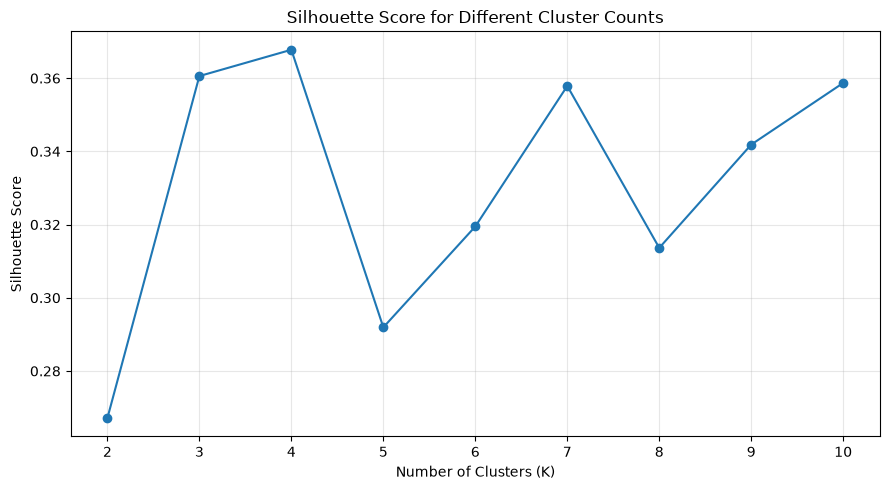

In [146]:

from sklearn.metrics import silhouette_score

# Sample 10,000 customers for evaluation
sample_size = min(10000, len(rfm_scaled))

rfm_sample = rfm_scaled.sample(
    n=sample_size,
    random_state=42
)

silhouette_scores = []

for k in range(2, 11):
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=4096,
        n_init=3
    )

    labels = model.fit_predict(rfm_sample)

    score = silhouette_score(
        rfm_sample,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different Cluster Counts")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 8. Model Evaluation

The K-Means clustering algorithm was used to segment customers based on three RFM metrics: Recency, Frequency, and Monetary Value. The number of clusters was selected by comparing the Elbow Method and Silhouette Scores for different values of K.

Among the tested values, K = 4 achieved the highest silhouette score of approximately 0.368. After fitting the final model, the silhouette score evaluated on a sample of 10,000 customers was approximately 0.355.

These results indicate moderate separation between customer groups, although some overlap exists. Therefore, the clusters provide useful insights into customer purchasing behavior, but they should not be considered perfectly distinct groups.


In [147]:

from sklearn.cluster import MiniBatchKMeans

# Build the final candidate model
kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=8192,
    n_init=5
)

# Assign a cluster to every customer
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("Clustering completed successfully!")
print("Total customers:", len(rfm))
print("Number of clusters:", rfm["Cluster"].nunique())


Clustering completed successfully!
Total customers: 884265
Number of clusters: 4


In [148]:

cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_summary = pd.DataFrame({
    "CustomerCount": cluster_counts,
    "Percentage": (
        cluster_counts / len(rfm) * 100
    ).round(2)
})

print(cluster_summary)


         CustomerCount  Percentage
Cluster                           
0               151283       17.11
1               290036       32.80
2               142600       16.13
3               300346       33.97


In [149]:

cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median")
    )
    .round(2)
)

print(cluster_profile)


         CustomerCount  AvgRecency  AvgFrequency  AvgMonetary  MedianRecency  \
Cluster                                                                        
0               151283       38.25          1.01       355.74           40.0   
1               290036       66.96          1.00       229.45           68.0   
2               142600       48.90          2.15      3378.65           47.0   
3               300346       58.63          1.00      3491.43           58.0   

         MedianFrequency  MedianMonetary  
Cluster                                   
0                    1.0          205.00  
1                    1.0          200.00  
2                    2.0         1426.95  
3                    1.0         1500.00  



## 9. Customer Segment Analysis

The customer segmentation model identified four distinct groups based on customer recency, transaction frequency, and total transaction amount.

### Cluster 0: Recently Active, Lower-Value Customers

These customers have a relatively low average recency of approximately 38 days, meaning their latest recorded transactions occurred more recently than those of the other clusters. Their average monetary value is approximately ₹356, and most have made only one recorded transaction.

**Interpretation:** These customers may be suitable for engagement campaigns that encourage repeat transactions and increase their overall activity.

### Cluster 1: Less Recently Active, Lower-Value Customers

This is the largest group of lower-value, mostly one-time customers. Their average recency is approximately 67 days, and their average monetary value is approximately ₹229.

**Interpretation:** These customers may need re-engagement campaigns or reminders designed to encourage future transactions.

### Cluster 2: Repeat, Higher-Value Customers

Customers in this segment have an average transaction frequency of approximately 2.15 and an average monetary value of approximately ₹3,379. Their average recency is approximately 49 days.

**Interpretation:** These customers have made more transactions and have a higher total transaction amount on average. They may be suitable for loyalty programs and personalized engagement.

### Cluster 3: Higher-Value, Mostly One-Time Customers

This segment has an average monetary value of approximately ₹3,491, but an average transaction frequency of only 1. Most customers in this group have made one recorded transaction.

**Interpretation:** These customers have relatively high total transaction amounts despite low transaction frequency. Follow-up engagement may help determine whether they can become repeat customers.

**Note:** These interpretations describe patterns in the available transaction records. They do not establish customer loyalty, profitability, or future behavior.


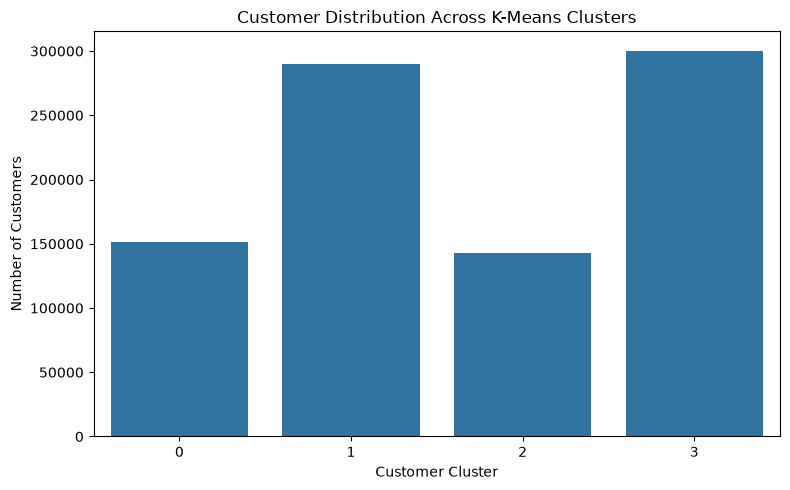

In [150]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x="Cluster")

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


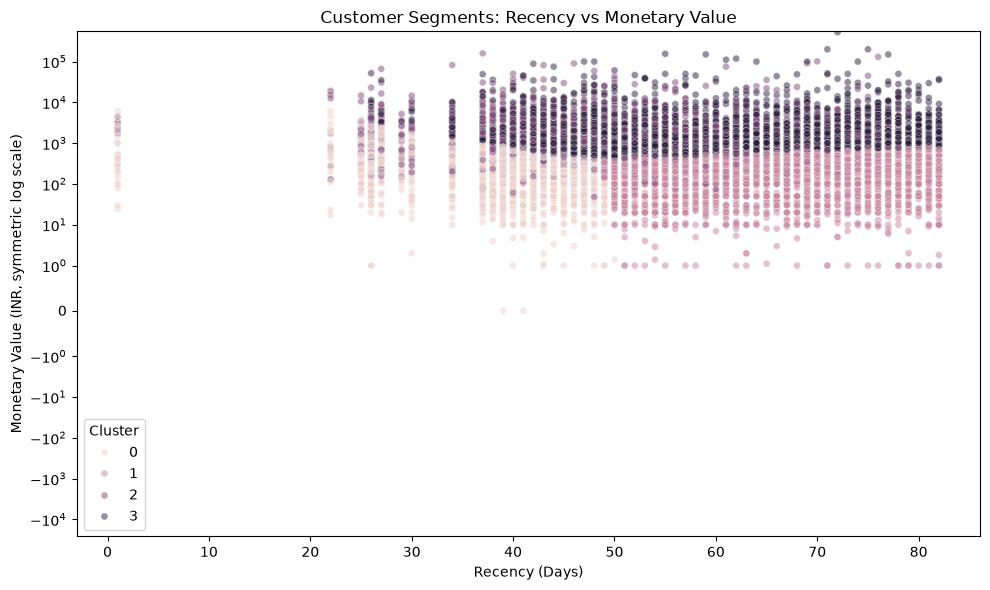

In [151]:

# Sample customers for visualization
plot_sample = rfm.sample(
    n=min(10000, len(rfm)),
    random_state=42
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    alpha=0.5,
    s=25
)

plt.yscale("symlog", linthresh=1)
plt.title("Customer Segments: Recency vs Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (INR, symmetric log scale)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


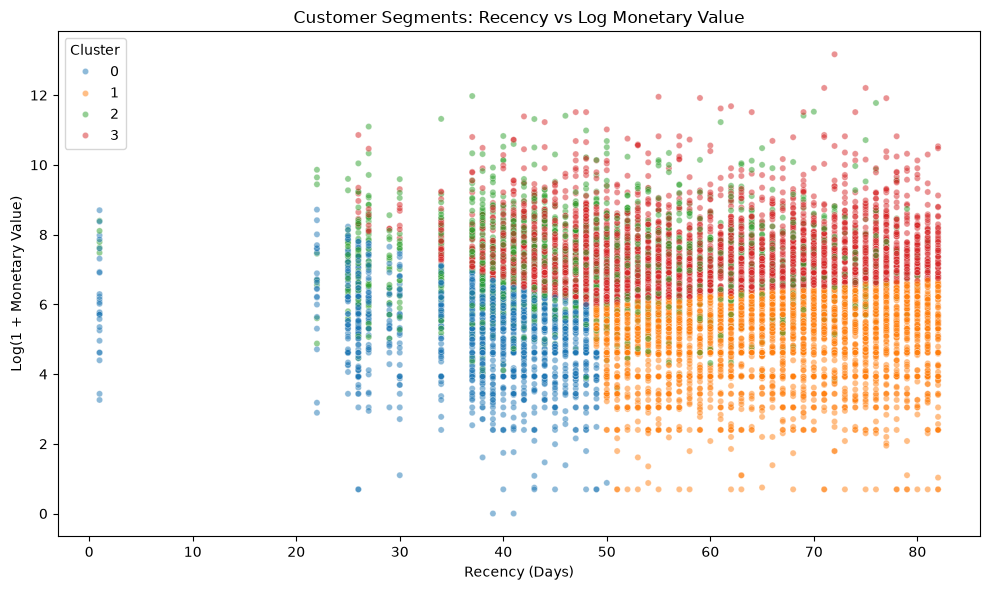

In [152]:

plot_sample = rfm.sample(
    n=min(10000, len(rfm)),
    random_state=42
).copy()

plot_sample["LogMonetary"] = np.log1p(
    plot_sample["Monetary"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_sample,
    x="Recency",
    y="LogMonetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.5,
    s=20
)

plt.title("Customer Segments: Recency vs Log Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Log(1 + Monetary Value)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [153]:

cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        MedianRecency=("Recency", "median"),
        AvgFrequency=("Frequency", "mean"),
        MedianFrequency=("Frequency", "median"),
        AvgMonetary=("Monetary", "mean"),
        MedianMonetary=("Monetary", "median")
    )
    .round(2)
)

display(cluster_profile)


,CustomerCount,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary
Cluster,,,,,,,
0,151283,38.25,40.0,1.01,1.0,355.74,205.00
1,290036,66.96,68.0,1.00,1.0,229.45,200.00
2,142600,48.90,47.0,2.15,2.0,3378.65,1426.95
3,300346,58.63,58.0,1.00,1.0,3491.43,1500.00



## 10. Business Recommendations

Based on the customer segments identified by the clustering model, the following strategies may be considered:

1. **Recently Active, Lower-Value Customers:** Encourage repeat transactions through relevant offers, reminders, and personalized communication.

2. **Less Recently Active, Lower-Value Customers:** Use targeted re-engagement campaigns to encourage customers to return and transact again.

3. **Repeat, Higher-Value Customers:** Consider loyalty initiatives and personalized services to maintain engagement and encourage continued activity.

4. **Higher-Value, Mostly One-Time Customers:** Develop follow-up strategies that encourage a second transaction and explore the needs of these customers.

5. **Continuous Monitoring:** Recalculate RFM metrics periodically and evaluate whether customer segments change over time.

These recommendations should be tested against actual customer responses before being implemented at scale.


In [154]:

from sklearn.metrics import silhouette_score

# Evaluate the final model on a sample of customers
sample_idx = rfm_scaled.sample(
    n=min(10000, len(rfm_scaled)),
    random_state=123
).index

sample_features = rfm_scaled.loc[sample_idx]
sample_labels = rfm.loc[sample_idx, "Cluster"]

final_silhouette = silhouette_score(
    sample_features,
    sample_labels
)

print(f"Final model silhouette score: {final_silhouette:.4f}")


Final model silhouette score: 0.3545


In [155]:

# Save the customer-level RFM data and cluster assignments
rfm.to_csv("customer_segments.csv", index=False)

# Save the cluster profile for the project report
cluster_profile.to_csv("cluster_summary.csv")

print("Files saved successfully:")
print("1. customer_segments.csv")
print("2. cluster_summary.csv")


Files saved successfully:
1. customer_segments.csv
2. cluster_summary.csv



## 11. Conclusion

This project applied data analysis and K-Means clustering to a bank transaction dataset to identify groups of customers with similar transaction behavior.

The dataset was inspected and cleaned, and exploratory data analysis was performed to understand transaction amounts, transaction frequency, missing values, and other data characteristics. Customer-level Recency, Frequency, and Monetary Value metrics were then calculated.

Log transformation and standardization were applied to prepare the RFM features for clustering. The Elbow Method and Silhouette Score were used to evaluate candidate cluster counts, and a four-cluster MiniBatch K-Means model was selected.

The final model grouped 884,265 customers into four segments with different recency, transaction frequency, and monetary-value patterns. The results demonstrate how data analysis and unsupervised machine learning can help summarize customer behavior and support targeted business strategies.

Although the clusters show useful patterns, their separation is moderate, and the dataset contains only a limited period of transaction history. Further analysis with longer-term data and additional customer attributes could improve the segmentation.


In [156]:

import os

print("Total customers segmented:", len(rfm))
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

print("\nMissing cluster assignments:", rfm["Cluster"].isna().sum())

print("\nOutput files:")
for filename in ["customer_segments.csv", "cluster_summary.csv"]:
    print(f"{filename}: {'Saved' if os.path.exists(filename) else 'Not found'}")


Total customers segmented: 884265

Customers in each cluster:
Cluster
0    151283
1    290036
2    142600
3    300346
Name: count, dtype: int64

Missing cluster assignments: 0

Output files:
customer_segments.csv: Saved
cluster_summary.csv: Saved
